<a href="https://colab.research.google.com/github/ale-rosselli/astro_notebooks/blob/main/ASTR119_Gaia.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Gaia Data

*this notebook was designed by Alejandra Rosselli-Calderon using resources by Aditya Sengupta and Rav Kaur (UCSC)*

The European Space Agency’s (ESA) Gaia telescope is an ambitious mission to chart a three-dimensional map of our Galaxy, the Milky Way, in the process revealing the composition, formation and evolution of the Galaxy. Gaia will provide unprecedented positional and radial velocity measurements with the accuracies needed to produce a stereoscopic and kinematic census of about one billion stars in our Galaxy and throughout the Local Group. This amounts to about 1 per cent of the Galactic stellar population.


### Main goals:


*   read in a .csv file
*   handle data using pands
*   plot the data (make a color-magnitude diagram)



In [ ]:
# as always, imports first
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt

Next, we are going to read in the data and make our first pandas dataframe.

In [ ]:
# the comma-separated values (csv) file is called pleiades.csv
# Use pandas to make a dataframe (df) with the data from this file.

#df = ...

<details>
  <summary><b>Click here for a hint</b></summary>
  <br>
  Use the <code>pd.read_csv()</code> function to load your dataset.
</details>

<details>
  <summary><b>Click here for the answer</b></summary>
  <br>
  <code>df = pd.read_csv("pleiades.csv")</code>
</details>

In [ ]:
#by doing df alone, we can take a peek at what we have inside of our dataframe
df

I don't like dealing with Nans, let's drop every row that has a Nan.

In [ ]:
df = df.dropna()

We should now have 217,506 rows.

### Parallax

Stellar parallax is the apparent shift of position (parallax) of any nearby star (or other object) against the background of distant stars.

parallax.svg

Let's take a look at one of the columns, parallax.


In [ ]:
## we can call the column as a property of our dataframe
df.parallax
#NOTE: this does not work if the name has spaces for example, and we need to use the square braket notation

In [ ]:
## we can also call it using parentheses
df['parallax']

These Pandas columns are similar to arrays, we can easily modify them like:

In [ ]:
df['parallax']*2

and we can also turn them into numpy arrays

In [ ]:
parallax_arr = np.array(df.parallax)
parallax_arr

What is the maximum parallax?

In [ ]:
#your answer here

What is the minimum parallax?

In [ ]:
#your answer here

<details>
  <summary><b>Click here for a hint</b></summary>
  <br>
  Pandas has a function to find the maximum and minimum. Alternatively, maybe other packages that we imported can help...
</details>

<details>
  <summary><b>Click here for the answer</b></summary>
  <br>
  <code>df.parallax.min()</code> or <code>np.min(df['parallax])</code> should give you the same answer. Change min to max to get the maximums.
</details>

## Let's make our first plot

Now that we are familiar with the dataframe, we will look at the data. What does it tells and what can we do to better understand it?

### Exercise 1: Map of the sky

The data we have has two columns, RA and DEC, that give information about the position of the stars in the sky. Make a scatter plot showing their positions in the sky.

In [ ]:
# your answer here

Ahhh! It looks like a huge blob. The reason is that we have too many things and they are all on top of each other. Let's clean it up. We are going to adjust the opacity based on the parallax using the alpha parameter. First we need to normalize the data to go from 0 to 1.

In [ ]:
normalized_parallax = (df['parallax'] - np.min(df['parallax'])) / (np.max(df['parallax']) - np.min(df['parallax']))

Now plot it with the normalized opacities (or 10% of it) to adjust. Make the scatter points small to help.  

In [ ]:
# your plot here


<details>
  <summary><b>Click here for the answer</b></summary>
  <br>
  <code>
  plt.scatter(df.ra, df.dec, alpha=0.2*normalized_parallax, s=2, color='orchid')

  plt.ylabel('DEC [deg]')

  plt.xlabel('RA [deg]')

  plt.show()
  </code>
</details>

### Exercise 2: What stars tell us

We will now make a color-magnitude diagram. This is similar to the Hertzsprung–Russell diagram (HR diagram).

In [ ]:
# your code here


<details>
  <summary><b>Click here for a hint</b></summary>
  <br>
  br_rp stands for blue photometer-red photometer (giving us the color) and phot_g_mean_mag is the magnitude in the green photometer.
</details>

<details>
  <summary><b>Click here for a hint</b></summary>
  <br>
  The way we plot magnitude is a bit weird, invert the y-axis so that the smallest numbers are above the larger numbers.
</details>

<details>
  <summary><b>Click here for the answer</b></summary>
  <br>
  <code>
  fig, ax = plt.subplots()

  ax.scatter(df['bp_rp'], df['phot_g_mean_mag'], s=2, alpha=0.2*normalized)

  ax.set_xlabel(r'BP - RP Color')
  
  ax.set_ylabel(r'Apparent Magnitude in G-band ')

  ax.invert_yaxis()
  </code>
</details>

It should look something like this:

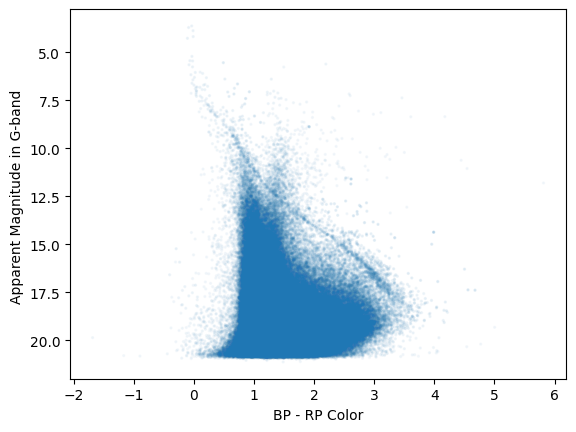

In [ ]:
#your plot here

# Extras

We are going to play with more Gaia data. We will use astroquery, which searches the Gaia database and selects the targets that fit our criteria. I will give you the query, but feel free to play around in the future. To learn more about queries, you can go [here.](https://datacarpentry.github.io/astronomy-python/instructor/aio.html)


In [ ]:
!pip install astroquery #we will use this package for our search of data
from astroquery.gaia import Gaia
from astropy.coordinates import SkyCoord
import astropy.units as u

We will select data that is good and useful. No need to understand how we chose the following, feel free to look into it.


In [ ]:
query = f"""
SELECT TOP 500000
    phot_g_mean_mag,
    bp_rp,
    parallax
FROM gaiadr3.gaia_source
WHERE parallax_over_error > 10
  AND parallax > 10
  AND phot_g_mean_flux_over_error > 50
  AND bp_rp IS NOT NULL
"""

In [ ]:
## time to run the query, this might take some time
print("Querying Gaia DR3 archive …")
job = Gaia.launch_job(query)
df   = job.get_results()
print(f"  → {len(df)} stars returned!")

Okay nice, time to calculate the first thing, distances in units of parseconds. We will calculate them based on the parallax.

In [ ]:
# your answer

<details>
  <summary><b>Click here for a hint</b></summary>
  <br>
  parallax in our dataframe has units of microarcseconds.
</details>



<details>
  <summary><b>Click here for the answer</b></summary>
  <br>
  <code> df["dist_pc"]    = 1000.0 / df["parallax"] </code>
</details>


Make a plot like we did above for color-magnitude of these stars.

In [ ]:
#your plot here


Nice! I did not tell you the absolute truth though. The information we have is the apparent magnitude, and we need the absolute magnitude (which is adjusted to account for farther stars looking less bright). We will have to calculate the absolute magnitude using the equation

$$ \text{apparent} - \text{absolute} = 5 (\log_{10} d - 1) $$

where d is the distance we found above.

We will now make a proper color magnitude diagram.

First, find the absolute magnitude in the g band.

<details>
  <summary><b>Click here for the answer</b></summary>
  <br>
  <code> df['absolute_g'] = df['phot_g_mean_mag'] - 5 * np.log10(df['dist_pc']) + 5  </code>
</details>

In [ ]:
# convert apparent magnitude to absolute magnitude

Now you can plot it like we did above. For an extra challenge, plot it using a 2D histogram where you have a colormap to signify the number of occurences.

<details>
  <summary><b>Click here for a hint</b></summary>
  <br>
  <code> plt.hist2d  </code> makes 2D histograms.
</details>

<details>
  <summary><b>Click here for the answer</b></summary>
  <br>
  <code>
fig, ax = plt.subplots()

plt.hist2d(df['bp_rp'], df['absolute_g'], bins=300, cmap='inferno', cmin=1)

ax.invert_yaxis()

plt.xlabel('Color (BP - RP) ')

plt.ylabel('Absolute Magnitude (M_G) ')

plt.colorbar(label='Number of Stars')

plt.show()  </code>
</details>

In [ ]:
# your answer here

When you are done, send me the plot! I would love to see it. There are many colormaps to play with, the number of bins and the dimensions of the plot can also help make it more or less clear.

## One last thing..

what is this color-magnitude plot telling us? what patterns do we see and what do these paterns mean?

This is a kind of plot that is very commonly used in astronomy, you should be able to understand it and interpret it. You can talk to me or look it up, it is always fun to learn something new.